# 06 — Alpha sweep: how does the walk change, and when does the skeleton break?

For every test walk: take its latent z from the trained **VAE** (notebook 04), move it along a speed direction d, and decode

$$z' = z + \alpha \cdot \sigma \cdot d \qquad \alpha = -3 \dots +3$$

(σ = spread of the training walks along d, so α is in "standard deviations").

**For each α the notebook measures:**

| How the walk changes | Is the skeleton still OK? |
|---|---|
| forward speed (m/s) | **bone lengths** stay the same as the original person's |
| cadence (steps/min) | **foot sliding**: feet moving while planted |
| stride length (m) | **floor penetration**: feet below the floor |
| | **floating**: both feet off the floor |
| | **jerk**: shaky, non-smooth motion |

A walk counts as **plausible** when all five checks stay within limits set from the data itself:
`TOL ×` the worst 5 % of (real walks, or the VAE's normal reconstructions, whichever is larger).
The **safe α range** is where at least `MIN_PLAUSIBLE_FRACTION` of walks pass.

**Directions tried** (all found on training people only, without retraining anything):
- **diff of means**: average z of fast walks − average z of slow walks
- **probe**: weight vector of a ridge regression z → speed
- **PCA axis**: the principal component of z most correlated with speed
- **random**: random directions, as a control (they should *not* change speed steadily)

The **speed-conditioned VAE** (notebook 05) gets the same checks. There, "α" means asking for the walk's own speed + α · (spread of training speeds).

## Settings

In [1]:
from pathlib import Path
import numpy as np

PRE_DIR    = Path(r"C:\Users\hasna\Documents\Good Practise\CMU\walking\preprocessed")
MODELS_DIR = PRE_DIR.parent / "models"
VAE_RUN    = "vae_full_z64_b1_s0"            # folder made by notebook 04 (full features, not no-root)
CVAE_RUN   = "cvae_full_z64_b1_ctl100_s0"    # folder made by notebook 05; None to skip

ALPHAS        = np.round(np.linspace(-3, 3, 13), 2)   # widen (e.g. -6..6, 25 steps) if nothing breaks within ±3
N_RANDOM_DIRS = 5
TOL           = 1.5     # limit = TOL x (95th percentile of real walks / normal reconstructions)
MIN_PLAUSIBLE_FRACTION = 0.8
# limits are never stricter than these (so tiny, invisible differences don't count as "broken")
MIN_LIMITS = dict(bone_error_pct=2.0, foot_sliding_cm_s=5.0, floor_penetration_cm=1.0, floating_cm=5.0, jerk=0.0)
MAX_TEST_WINDOWS = None   # e.g. 500 to make it faster
SEED          = 0

OUT_DIR = MODELS_DIR / "edit_analysis" / f"{VAE_RUN}__{CVAE_RUN}"

In [2]:
import json, warnings
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from scipy.stats import spearmanr
warnings.filterwarnings("ignore", message=".*[Ii]ll-conditioned.*")
warnings.filterwarnings("ignore", category=RuntimeWarning)

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
OUT_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)

cfg  = json.loads((PRE_DIR / "config.json").read_text())
norm = np.load(PRE_DIR / "normalization.npz")
FPS, BONES, FEATS, JN = cfg["TARGET_FPS"], np.array(cfg["BONES"]), cfg["FEATURES"], cfg["JOINT_NAMES"]
MEAN, STD = norm["mean"], norm["std"]
CONTACT = [i for i, f in enumerate(FEATS) if f.startswith("contact_")]
FWD = FEATS.index("root_vel_forward")
FEET = [JN.index(n) for n in ["L_ankle", "R_ankle", "L_foot", "R_foot"]]
FOOT_H = np.array([cfg["CONTACT_HEIGHT"][n] for n in ["L_ankle", "R_ankle", "L_foot", "R_foot"]])
LA, RA = JN.index("L_ankle"), JN.index("R_ankle")

te = np.load(PRE_DIR / "test.npz", allow_pickle=True)
te_meta = pd.read_csv(PRE_DIR / "test_meta.csv")
sel = np.arange(len(te_meta))
if MAX_TEST_WINDOWS and len(sel) > MAX_TEST_WINDOWS:
    sel = np.sort(rng.choice(sel, MAX_TEST_WINDOWS, replace=False))
X_te, J_te, te_meta = te["X"][sel], te["joints"][sel], te_meta.iloc[sel].reset_index(drop=True)
tr_meta = pd.read_csv(PRE_DIR / "train_meta.csv")
print(f"{len(sel)} test windows, {te_meta.person.nunique()} test people")

591 test windows, 13 test people


## Load the trained models
The classes are the same as in notebooks 04 and 05; sizes are read from the saved checkpoints.

In [3]:
class ResBlock(nn.Module):
    def __init__(self, c, k=5):
        super().__init__()
        self.net = nn.Sequential(nn.GroupNorm(8, c), nn.GELU(), nn.Conv1d(c, c, k, padding=k // 2),
                                 nn.GroupNorm(8, c), nn.GELU(), nn.Conv1d(c, c, k, padding=k // 2))
    def forward(self, x):
        return x + self.net(x)

def _encoder(D_in, H, T4, latent):
    return nn.Sequential(nn.Conv1d(D_in, H, 5, padding=2), ResBlock(H),
                         nn.Conv1d(H, H, 4, stride=2, padding=1), ResBlock(H),
                         nn.Conv1d(H, H, 4, stride=2, padding=1), ResBlock(H),
                         nn.Flatten(), nn.Linear(H * T4, 2 * latent))

def _decoder(H, D):
    return nn.Sequential(ResBlock(H), nn.ConvTranspose1d(H, H, 4, stride=2, padding=1),
                         ResBlock(H), nn.ConvTranspose1d(H, H, 4, stride=2, padding=1),
                         ResBlock(H), nn.GroupNorm(8, H), nn.GELU(), nn.Conv1d(H, D, 5, padding=2))

class MotionVAE(nn.Module):
    def __init__(self, D, T, latent, H):
        super().__init__()
        self.T4, self.H = T // 4, H
        self.enc = _encoder(D, H, self.T4, latent)
        self.dec_in = nn.Linear(latent, H * self.T4)
        self.dec = _decoder(H, D)
    def encode(self, x):
        mu, logvar = self.enc(x.transpose(1, 2)).chunk(2, dim=-1)
        return mu, logvar
    def decode(self, z):
        return self.dec(self.dec_in(z).view(-1, self.H, self.T4)).transpose(1, 2)

class SpeedCVAE(nn.Module):
    def __init__(self, D, T, latent, H):
        super().__init__()
        self.T4, self.H = T // 4, H
        self.enc = _encoder(D + 1, H, self.T4, latent)
        self.dec_in = nn.Sequential(nn.Linear(latent + 1, H * self.T4))
        self.dec = _decoder(H, D)
    def encode(self, x, c):
        cc = c[:, None, None].expand(-1, x.shape[1], 1)
        mu, logvar = self.enc(torch.cat([x, cc], -1).transpose(1, 2)).chunk(2, dim=-1)
        return mu, logvar
    def decode(self, z, c):
        return self.dec(self.dec_in(torch.cat([z, c[:, None]], -1)).view(-1, self.H, self.T4)).transpose(1, 2)

def load(run, cls):
    ck = torch.load(MODELS_DIR / run / "model.pt", map_location="cpu", weights_only=False)
    m = cls(ck["D"], ck["T"], ck["LATENT_DIM"], ck["HIDDEN"])
    m.load_state_dict(ck["state_dict"]); m.to(device).eval()
    return m, ck

vae, vae_ck = load(VAE_RUN, MotionVAE)
assert not vae_ck.get("USE_NOROOT", False), "Use a full-feature VAE run (USE_NOROOT=False): speed is measured from the root channel."
cvae, cvae_ck = load(CVAE_RUN, SpeedCVAE) if CVAE_RUN and (MODELS_DIR / CVAE_RUN / "model.pt").exists() else (None, None)
print("VAE:", VAE_RUN, "| CVAE:", CVAE_RUN if cvae is not None else "not found, skipped")

def denorm(xn):
    x = xn * STD + MEAN
    x[..., CONTACT] = 1 / (1 + np.exp(-xn[..., CONTACT]))
    return x

@torch.no_grad()
def vae_decode(Z, bs=512):
    return denorm(np.concatenate([vae.decode(torch.tensor(Z[i:i + bs], dtype=torch.float32, device=device)).cpu().numpy()
                                  for i in range(0, len(Z), bs)]))

@torch.no_grad()
def cvae_decode(Z, speeds, bs=512):
    c = (np.asarray(speeds, np.float32) - cvae_ck["SP_MEAN"]) / cvae_ck["SP_STD"]
    return denorm(np.concatenate([cvae.decode(torch.tensor(Z[i:i + bs], dtype=torch.float32, device=device),
                                              torch.tensor(c[i:i + bs], dtype=torch.float32, device=device)).cpu().numpy()
                                  for i in range(0, len(Z), bs)]))

@torch.no_grad()
def encode(model, X, c=None, bs=512):
    out = []
    for i in range(0, len(X), bs):
        xb = torch.tensor(X[i:i + bs], dtype=torch.float32, device=device)
        mu = model.encode(xb)[0] if c is None else model.encode(xb, torch.tensor(c[i:i + bs], dtype=torch.float32, device=device))[0]
        out.append(mu.cpu().numpy())
    return np.concatenate(out)

VAE: vae_full_z64_b1_s0 | CVAE: cvae_full_z64_b1_ctl100_s0


## Measurements (vectorised over many walks at once)
- **Speed**: mean of the decoded root forward-speed channel.
- **Cadence / stride**: stride frequency from the repeating left–right ankle swing (autocorrelation); cadence = 2 × 60 × frequency, stride length = speed / frequency. In 2 s windows these are rough estimates, so look at averages over many walks.
- **Bone error**: average % difference of each bone's length from the same bone in the original window.
- **Foot sliding**: horizontal speed of a foot joint while it is low enough to count as planted (cm/s).
- **Floor penetration**: how far the lowest foot joint goes below the floor (cm, averaged over frames).
- **Floating**: height of the lowest foot joint (cm, averaged over frames).
- **Jerk**: average size of the third derivative of joint positions (m/s³).

In [4]:
def recover_joints_batch(x, fps=FPS):
    # (N, T, D) de-normalised full features -> (N, T, 22, 3)
    N, T_ = x.shape[:2]
    th = np.concatenate([np.zeros((N, 1)), np.cumsum(x[:, :-1, 3], 1) / fps], 1)
    c, s = np.cos(th), np.sin(th)
    vx = c * x[..., 1] - s * x[..., 2]; vy = s * x[..., 1] + c * x[..., 2]
    rx = np.concatenate([np.zeros((N, 1)), np.cumsum(vx[:, :-1], 1) / fps], 1)
    ry = np.concatenate([np.zeros((N, 1)), np.cumsum(vy[:, :-1], 1) / fps], 1)
    loc = x[..., 4:67].reshape(N, T_, 21, 3).astype(np.float64)
    gx = c[..., None] * loc[..., 0] - s[..., None] * loc[..., 1] + rx[..., None]
    gy = s[..., None] * loc[..., 0] + c[..., None] * loc[..., 1] + ry[..., None]
    joints = np.stack([gx, gy, loc[..., 2]], -1)
    root = np.stack([rx, ry, x[..., 0]], -1)[:, :, None]
    return np.concatenate([root, joints], 2)

def bone_lengths(J):
    return np.linalg.norm(J[:, :, BONES[:, 0]] - J[:, :, BONES[:, 1]], axis=-1)   # (N, T, B)

REF_BONES = bone_lengths(J_te).mean(1)   # each test person's own bone lengths (N, B)

def stride_frequency(J, fps=FPS):
    # stride frequency (Hz) from the autocorrelation of the left-right ankle gap along the walking direction
    sgn = J[:, :, LA, 0] - J[:, :, RA, 0]
    sgn = sgn - sgn.mean(1, keepdims=True)
    N, T_ = sgn.shape
    F_ = np.fft.rfft(sgn, 2 * T_, axis=1)
    ac = np.fft.irfft(np.abs(F_) ** 2, axis=1)[:, :T_]
    ac = ac / (ac[:, :1] + 1e-12) * T_ / (T_ - np.arange(T_))          # unbiased
    lo, hi = int(0.6 * fps), min(int(1.8 * fps), T_ - 12)
    k = lo + np.argmax(ac[:, lo:hi], 1)
    ok = ac[np.arange(N), k] > 0.2
    return np.where(ok, fps / k, np.nan)

def measure(x, ref_bones=REF_BONES, fps=FPS):
    J = recover_joints_batch(x)
    speed = x[..., FWD].mean(1)
    f = stride_frequency(J)
    feet = J[:, :, FEET]                                    # (N, T, 4, 3)
    h = feet[..., 2]
    vh = np.linalg.norm(np.diff(feet[..., :2], axis=1), axis=-1) * fps
    planted = h[:, 1:] < FOOT_H
    skate = (vh * planted).sum((1, 2)) / np.maximum(planted.sum((1, 2)), 1) * 100
    lowest = h.min(2)                                       # (N, T)
    L = bone_lengths(J)
    jerk = np.linalg.norm(np.diff(J, n=3, axis=1), axis=-1).mean((1, 2)) * fps ** 3
    return pd.DataFrame(dict(
        speed=speed, cadence=2 * 60 * f, stride_length=speed / f,
        bone_error_pct=(np.abs(L - ref_bones[:, None]) / ref_bones[:, None]).mean((1, 2)) * 100,
        foot_sliding_cm_s=skate,
        floor_penetration_cm=np.clip(-lowest, 0, None).mean(1) * 100,
        floating_cm=np.clip(lowest, 0, None).mean(1) * 100,
        jerk=jerk))

CHECKS = ["bone_error_pct", "foot_sliding_cm_s", "floor_penetration_cm", "floating_cm", "jerk"]

## Limits: what counts as "broken"?
Measured on the **real** test walks and on the VAE's **normal reconstructions** (α = 0). Limit = `TOL` × the larger 95th percentile, but never stricter than `MIN_LIMITS`. Real walks have 0 % bone error by definition, so that limit comes from the reconstructions.

In [5]:
x_real = X_te * STD + MEAN
real = measure(x_real)
mu_vae = encode(vae, X_te)
recon0 = measure(vae_decode(mu_vae))

limits = {}
for c in CHECKS:
    limits[c] = max(TOL * max(np.nanpercentile(real[c], 95), np.nanpercentile(recon0[c], 95)), MIN_LIMITS[c], 1e-6)
lim_tab = pd.DataFrame({"real walks (median)": real[CHECKS].median(), "real walks (p95)": real[CHECKS].quantile(.95),
                        "VAE reconstruction (median)": recon0[CHECKS].median(), "VAE reconstruction (p95)": recon0[CHECKS].quantile(.95),
                        "LIMIT": pd.Series(limits)})
print(lim_tab.round(3).to_string())

def plausible(df):
    return np.all([df[c].values <= limits[c] for c in CHECKS], axis=0)

print(f"\nPlausible: real walks {plausible(real).mean():.0%}, VAE reconstructions {plausible(recon0).mean():.0%}")
print(f"Gait on real test walks: speed {real.speed.mean():.2f} m/s, cadence {np.nanmean(real.cadence):.0f} steps/min, "
      f"stride {np.nanmean(real.stride_length):.2f} m")

                      real walks (median)  real walks (p95)  VAE reconstruction (median)  VAE reconstruction (p95)    LIMIT
bone_error_pct                      0.000             0.000                        2.452                     8.848   13.272
foot_sliding_cm_s                  58.053            75.137                       59.946                    81.911  122.866
floor_penetration_cm                0.000             0.052                        0.000                     0.022    1.000
floating_cm                         1.190             5.059                        1.673                     3.736    7.588
jerk                               85.977           116.521                      262.607                   632.284  948.426

Plausible: real walks 100%, VAE reconstructions 98%
Gait on real test walks: speed 0.73 m/s, cadence 92 steps/min, stride 1.02 m


## Speed directions in the VAE latent space (from training people only)

In [6]:
lat_tr = np.load(MODELS_DIR / VAE_RUN / "latents_train.npz", allow_pickle=True)
lat_va = np.load(MODELS_DIR / VAE_RUN / "latents_val.npz", allow_pickle=True)
Ztr, ytr = lat_tr["mu"], lat_tr["speed"]
Zva, yva = lat_va["mu"], lat_va["speed"]
unit = lambda v: v / np.linalg.norm(v)

dirs = {}
q_lo, q_hi = np.percentile(ytr, [25, 75])
dirs["diff of means"] = unit(Ztr[ytr >= q_hi].mean(0) - Ztr[ytr <= q_lo].mean(0))

best = None
for a in [0.01, 0.1, 1, 10, 100, 1000]:
    p = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Ztr, ytr)
    v = r2_score(yva, p.predict(Zva))
    if best is None or v > best[0]:
        best = (v, p)
dirs["probe"] = unit(best[1][-1].coef_ / best[1][0].scale_)

pca = PCA().fit(Ztr)
P = pca.transform(Ztr)
corr = np.array([np.corrcoef(P[:, k], ytr)[0, 1] for k in range(P.shape[1])])
k = int(np.nanargmax(np.abs(corr)))
dirs[f"PCA axis {k + 1}"] = unit(pca.components_[k] * np.sign(corr[k]))

for r in range(N_RANDOM_DIRS):
    dirs[f"random {r + 1}"] = unit(rng.standard_normal(Ztr.shape[1]))

# point every direction towards "faster" on the training data, and get its spread σ
sigma = {}
for name, d in dirs.items():
    if not name.startswith("random") and np.corrcoef(Ztr @ d, ytr)[0, 1] < 0:
        dirs[name] = -d
    sigma[name] = float((Ztr @ dirs[name]).std())

cos = pd.DataFrame([[float(dirs[a] @ dirs[b]) for b in dirs if not b.startswith("random")] for a in dirs if not a.startswith("random")],
                   index=[a for a in dirs if not a.startswith("random")], columns=[a for a in dirs if not a.startswith("random")])
print("cosine similarity between the directions (1 = identical):")
print(cos.round(2).to_string())
np.savez(OUT_DIR / "directions.npz", **{n.replace(" ", "_"): d for n, d in dirs.items()})

cosine similarity between the directions (1 = identical):
               diff of means  probe  PCA axis 3
diff of means           1.00   0.93        0.59
probe                   0.93   1.00        0.57
PCA axis 3              0.59   0.57        1.00


## Run the sweep
Every test walk × every α × every direction (and the CVAE).

In [7]:
rows, per_window = [], {}
def record(model, direction, alpha, df):
    ok = plausible(df)
    per_window[model, direction, alpha] = df.assign(plausible=ok)
    rows.append(dict(model=model, direction=direction, alpha=alpha,
                     speed=df.speed.mean(), speed_sd=df.speed.std(),
                     cadence=np.nanmean(df.cadence), stride_length=np.nanmean(df.stride_length),
                     plausible_fraction=ok.mean(),
                     **{c: df[c].median() for c in CHECKS},
                     **{f"fail_{c}": (df[c].values > limits[c]).mean() for c in CHECKS}))

for name, d in dirs.items():
    for a in ALPHAS:
        record("VAE", name, a, measure(vae_decode(mu_vae + a * sigma[name] * d)))
    print("done:", name)

if cvae is not None:
    true_speed = te_meta.fwd_speed_mps.values
    sp_sd = float(tr_meta.fwd_speed_mps.std())
    mu_c = encode(cvae, X_te, (true_speed - cvae_ck["SP_MEAN"]) / cvae_ck["SP_STD"])
    for a in ALPHAS:
        record("CVAE", "requested speed", a, measure(cvae_decode(mu_c, true_speed + a * sp_sd)))
    print("done: CVAE (α = own speed + α × %.2f m/s)" % sp_sd)

sweep = pd.DataFrame(rows)
sweep.to_csv(OUT_DIR / "sweep_summary.csv", index=False)

done: diff of means
done: probe
done: PCA axis 3
done: random 1
done: random 2
done: random 3
done: random 4
done: random 5
done: CVAE (α = own speed + α × 0.26 m/s)


## Safe α range and how far speed can be pushed
Starting at α = 0 and moving outwards, the safe range ends at the first α where fewer than `MIN_PLAUSIBLE_FRACTION` of walks pass all checks.

In [8]:
def safe_range(g):
    g = g.set_index("alpha").sort_index()
    ok = g.plausible_fraction >= MIN_PLAUSIBLE_FRACTION
    if not ok.get(0.0, False):
        return np.nan, np.nan
    lo = hi = 0.0
    for a in sorted(a for a in g.index if a > 0):
        if not ok[a]: break
        hi = a
    for a in sorted((a for a in g.index if a < 0), reverse=True):
        if not ok[a]: break
        lo = a
    return lo, hi

summary = []
for (m, dname), g in sweep.groupby(["model", "direction"], sort=False):
    lo, hi = safe_range(g)
    gi = g.set_index("alpha")
    rho = spearmanr(g.alpha, g.speed)[0]
    pw = np.stack([per_window[m, dname, a].speed.values for a in ALPHAS], 1)
    rho_w = np.nanmean([spearmanr(ALPHAS, r)[0] for r in pw])
    summary.append(dict(model=m, direction=dname, safe_alpha_min=lo, safe_alpha_max=hi,
                        speed_at_safe_min=gi.speed.get(lo, np.nan), speed_at_0=gi.speed.get(0.0, np.nan),
                        speed_at_safe_max=gi.speed.get(hi, np.nan),
                        safe_speed_range=gi.speed.get(hi, np.nan) - gi.speed.get(lo, np.nan),
                        slope_m_s_per_alpha=np.polyfit(g.alpha, g.speed, 1)[0],
                        monotonic_per_walk=rho_w,
                        cadence_change_pct=100 * (gi.cadence.get(hi, np.nan) / gi.cadence.get(lo, np.nan) - 1),
                        stride_change_pct=100 * (gi.stride_length.get(hi, np.nan) / gi.stride_length.get(lo, np.nan) - 1)))
summary = pd.DataFrame(summary)
summary.to_csv(OUT_DIR / "safe_ranges.csv", index=False)
show = summary.copy()
show["random"] = show.direction.str.startswith("random")
print(show.drop(columns="random").round(3).to_string(index=False))

model       direction  safe_alpha_min  safe_alpha_max  speed_at_safe_min  speed_at_0  speed_at_safe_max  safe_speed_range  slope_m_s_per_alpha  monotonic_per_walk  cadence_change_pct  stride_change_pct
  VAE   diff of means            -3.0             3.0              0.202       0.745              1.388             1.186                0.201               1.000              -1.827            500.314
  VAE           probe            -3.0             3.0              0.233       0.745              1.342             1.109                0.187               1.000               0.192            410.644
  VAE      PCA axis 3            -3.0             3.0              0.405       0.745              1.152             0.747                0.127               1.000               0.661            149.936
  VAE        random 1            -3.0             3.0              0.731       0.745              0.759             0.028                0.005               0.269               0.405          

## 1. Does speed change, and how? (speed, cadence, stride vs. α)

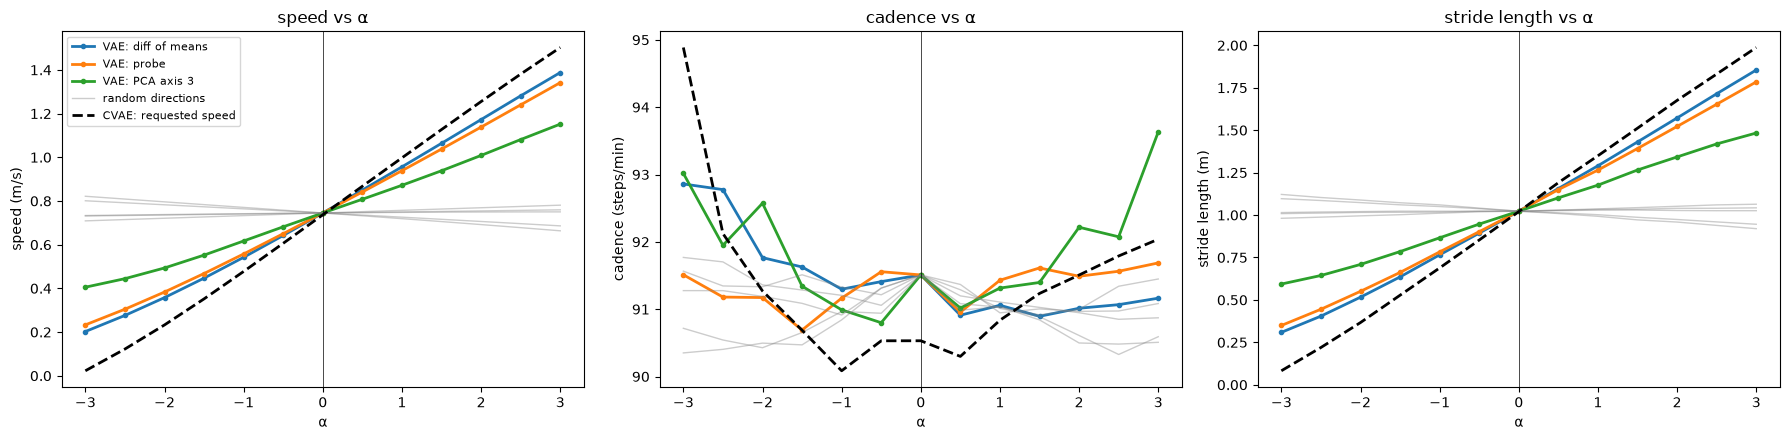

In [9]:
main = [n for n in dirs if not n.startswith("random")]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for n in dirs:
    g = sweep[(sweep.model == "VAE") & (sweep.direction == n)]
    rnd = n.startswith("random")
    kw = dict(color="grey", alpha=.4, lw=1, label="random directions" if n == "random 1" else None) if rnd else dict(lw=2, marker="o", ms=3, label=f"VAE: {n}")
    for a_, col in zip(ax, ["speed", "cadence", "stride_length"]):
        a_.plot(g.alpha, g[col], **kw)
if cvae is not None:
    g = sweep[sweep.model == "CVAE"]
    for a_, col in zip(ax, ["speed", "cadence", "stride_length"]):
        a_.plot(g.alpha, g[col], "k--", lw=2, label="CVAE: requested speed")
for a_, col, unit_ in zip(ax, ["speed", "cadence", "stride_length"], ["m/s", "steps/min", "m"]):
    a_.set(xlabel="α", ylabel=f"{col.replace('_', ' ')} ({unit_})", title=f"{col.replace('_', ' ')} vs α"); a_.axvline(0, color="k", lw=.5)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 2. Is the skeleton still OK? (each check vs. α)
Dashed line = limit. Shaded = safe α range of the best direction.

detailed plots use the direction: diff of means


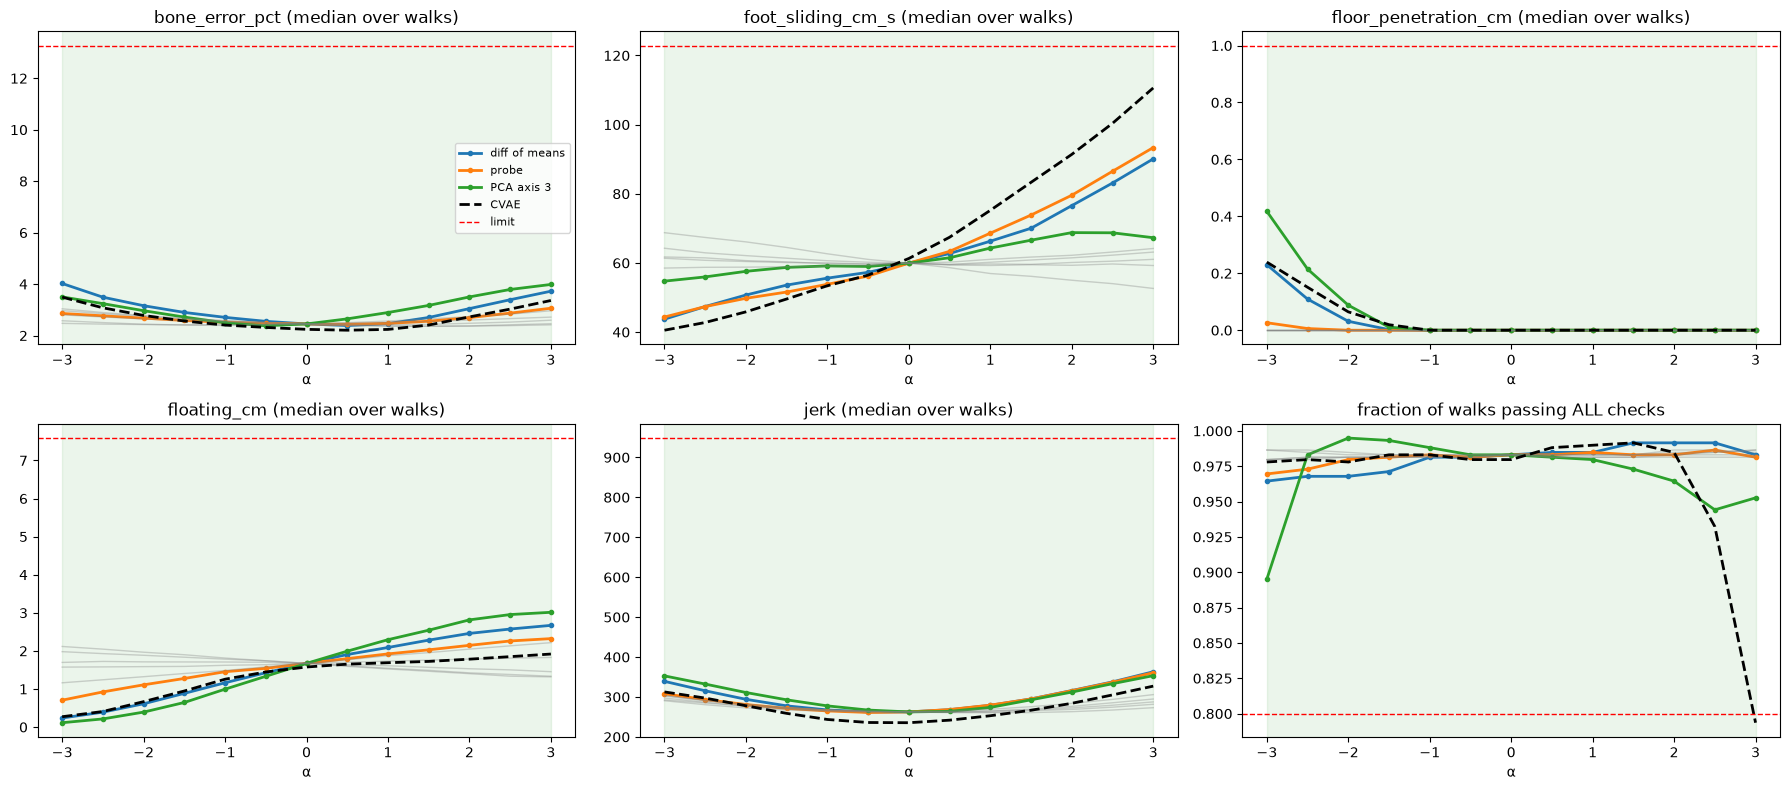

In [10]:
# the direction with the largest safe speed range is used for the detailed plots
pick = summary[(summary.model == "VAE") & ~summary.direction.str.startswith("random")] \
    .sort_values("safe_speed_range", ascending=False).direction.iloc[0]
print("detailed plots use the direction:", pick)
lo, hi = summary.set_index(["model", "direction"]).loc[("VAE", pick), ["safe_alpha_min", "safe_alpha_max"]]
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for a_, c in zip(axes.ravel(), CHECKS + ["plausible_fraction"]):
    for n in dirs:
        g = sweep[(sweep.model == "VAE") & (sweep.direction == n)]
        if n.startswith("random"):
            a_.plot(g.alpha, g[c], color="grey", alpha=.35, lw=1)
        else:
            a_.plot(g.alpha, g[c], lw=2, marker="o", ms=3, label=n)
    if cvae is not None:
        g = sweep[sweep.model == "CVAE"]; a_.plot(g.alpha, g[c], "k--", lw=2, label="CVAE")
    if c in limits:
        a_.axhline(limits[c], color="r", ls="--", lw=1, label="limit")
        a_.set_title(f"{c} (median over walks)")
    else:
        a_.axhline(MIN_PLAUSIBLE_FRACTION, color="r", ls="--", lw=1); a_.set_title("fraction of walks passing ALL checks")
    if np.isfinite(lo):
        a_.axvspan(lo, hi, color="green", alpha=.08)
    a_.set_xlabel("α")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. VAE direction vs. speed-conditioned VAE at the same speed change
x-axis = how much faster/slower the walks got on average (measured, not requested). Higher curve = more walks stay intact for that speed change.

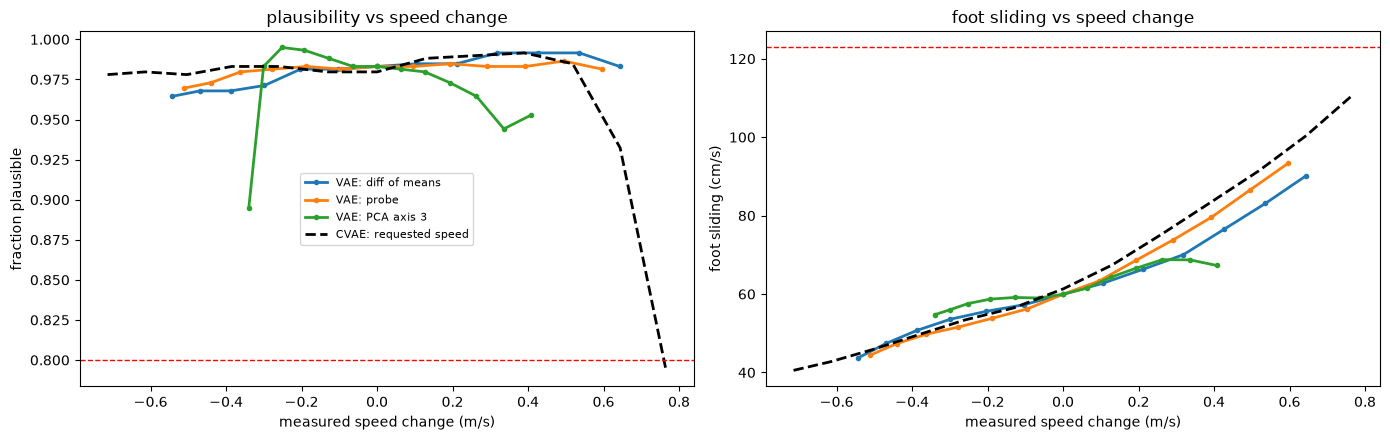

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for (m, n), g in sweep.groupby(["model", "direction"], sort=False):
    if n.startswith("random"): continue
    d_speed = g.speed - g.set_index("alpha").speed[0.0]
    style = dict(ls="--", color="k") if m == "CVAE" else dict(marker="o", ms=3)
    ax[0].plot(d_speed, g.plausible_fraction, lw=2, label=f"{m}: {n}", **style)
    ax[1].plot(d_speed, g.foot_sliding_cm_s, lw=2, label=f"{m}: {n}", **style)
ax[0].axhline(MIN_PLAUSIBLE_FRACTION, color="r", ls="--", lw=1)
ax[0].set(xlabel="measured speed change (m/s)", ylabel="fraction plausible", title="plausibility vs speed change")
ax[1].axhline(limits["foot_sliding_cm_s"], color="r", ls="--", lw=1)
ax[1].set(xlabel="measured speed change (m/s)", ylabel="foot sliding (cm/s)", title="foot sliding vs speed change")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 4. Stick figures along α
One test walk edited with the best direction. Each row lists its measurements; failed checks are named in red.

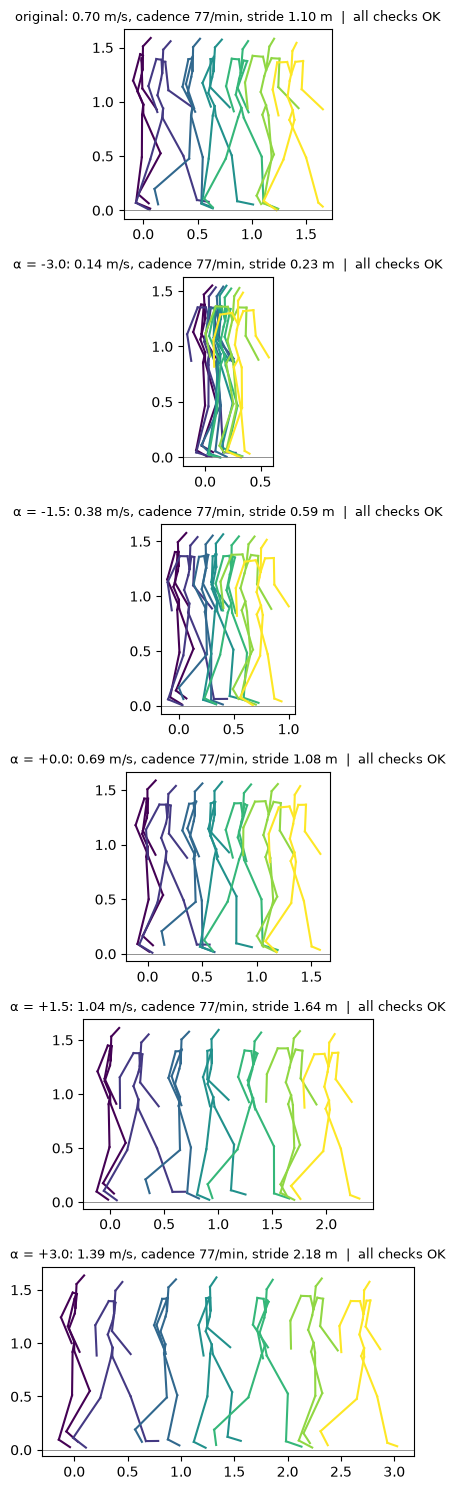

In [12]:
def draw(ax, P, color, lw=1.5):
    for j, p in BONES:
        ax.plot([P[j, 0], P[p, 0]], [P[j, 2], P[p, 2]], color=color, lw=lw)

i = int(np.argsort(te_meta.fwd_speed_mps.values)[len(te_meta) // 2])     # a walk of median speed
show_alphas = [a for a in [-3.0, -1.5, 0.0, 1.5, 3.0] if a in set(ALPHAS)]
fig, axes = plt.subplots(len(show_alphas) + 1, 1, figsize=(13, 2.5 * (len(show_alphas) + 1)))
rows_ = [("original", x_real[i:i + 1])] + [(f"α = {a:+.1f}", vae_decode(mu_vae[i:i + 1] + a * sigma[pick] * dirs[pick])) for a in show_alphas]
for ax, (lab, x) in zip(axes, rows_):
    J3 = recover_joints_batch(x)[0]
    m = measure(x, REF_BONES[i:i + 1]).iloc[0]
    failed = [c for c in CHECKS if m[c] > limits[c]]
    for k, t in enumerate(np.linspace(0, len(J3) - 1, 7).astype(int)):
        draw(ax, J3[t], "tab:red" if failed else plt.cm.viridis(k / 6))
    ax.axhline(0, color="grey", lw=.6); ax.set_aspect("equal")
    ax.set_title(f"{lab}: {m.speed:.2f} m/s, cadence {m.cadence:.0f}/min, stride {m.stride_length:.2f} m  |  "
                 + ("all checks OK" if not failed else "FAILED: " + ", ".join(failed)),
                 fontsize=9, color="tab:red" if failed else "black")
plt.tight_layout(); plt.show()

## Which check fails first?
For the best direction: the share of walks failing each check at every α. This shows *how* the skeleton breaks when pushed too far.

       bone_error_pct  foot_sliding_cm_s  floor_penetration_cm  floating_cm  jerk
alpha                                                                            
-3.0                3                  0                     0            0     0
-2.5                3                  0                     0            0     0
-2.0                3                  0                     0            0     0
-1.5                3                  0                     0            0     0
-1.0                2                  0                     0            0     0
-0.5                2                  0                     0            0     0
 0.0                1                  0                     0            0     0
 0.5                1                  0                     0            0     0
 1.0                1                  1                     0            0     0
 1.5                0                  1                     0            0     0
 2.0            

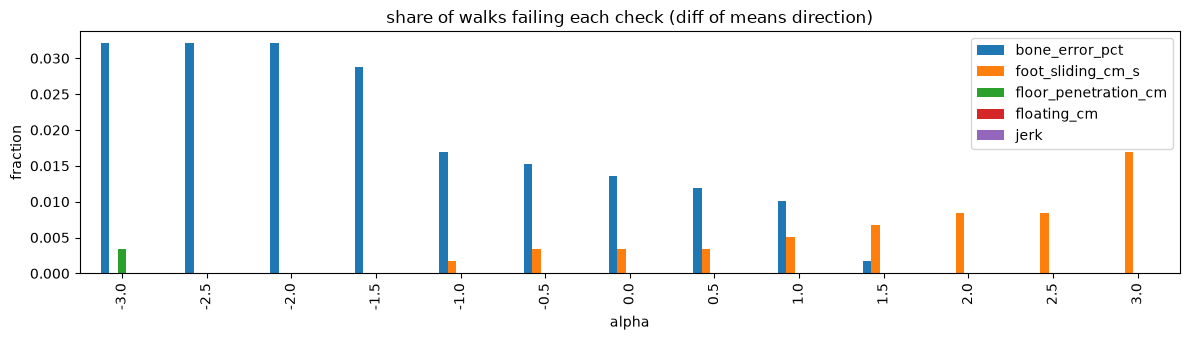

In [13]:
g = sweep[(sweep.model == "VAE") & (sweep.direction == pick)].set_index("alpha")
fails = g[[f"fail_{c}" for c in CHECKS]].rename(columns=lambda c: c[5:])
print((fails * 100).round(0).astype(int).to_string())
fails.plot(kind="bar", stacked=False, figsize=(12, 3.5), title=f"share of walks failing each check ({pick} direction)")
plt.ylabel("fraction"); plt.tight_layout(); plt.show()

## Save

In [14]:
best_dir = summary[(summary.model == "VAE") & ~summary.direction.str.startswith("random")].sort_values("safe_speed_range", ascending=False).iloc[0]
out = dict(vae_run=VAE_RUN, cvae_run=CVAE_RUN if cvae is not None else None, tol=TOL, min_plausible_fraction=MIN_PLAUSIBLE_FRACTION,
           limits={k: float(v) for k, v in limits.items()}, n_test_windows=int(len(sel)),
           real_plausible_fraction=float(plausible(real).mean()), recon_plausible_fraction=float(plausible(recon0).mean()),
           best_vae_direction=best_dir.direction,
           safe_ranges=summary.replace({np.nan: None}).to_dict(orient="records"))
(OUT_DIR / "results.json").write_text(json.dumps(out, indent=2, default=float))
print("saved to", OUT_DIR)
print(sorted(p.name for p in OUT_DIR.iterdir()))

saved to C:\Users\hasna\Documents\Good Practise\CMU\walking\models\edit_analysis\vae_full_z64_b1_s0__cvae_full_z64_b1_ctl100_s0
['directions.npz', 'results.json', 'safe_ranges.csv', 'sweep_summary.csv']


## How to read the results
- **Speed vs α:** the real directions should rise steadily; the **random** ones should stay flat. If a random direction changes speed as much as the probe, the "speed direction" isn't special.
- **Cadence vs stride:** shows *how* the edit speeds up the walk. Real people mostly lengthen their stride at moderate speeds and step faster at high speeds. If only cadence changes, the edit behaves like a playback speed-up.
- **Safe α range / safe speed range** (table): your main numbers. They say how far speed can be changed before the skeleton breaks.
- **Which check fails first:** foot sliding usually goes first (the body moves faster than the legs step). Bone error rising means the decoder is stretching the body.
- **VAE vs CVAE at the same speed change:** if the VAE direction stays plausible about as long as the CVAE, a simple post-hoc direction is about as good as a model trained for speed control. That's a strong result for the paper.
- Run this for every seed (`VAE_RUN = "..._s1"` etc.) and report mean ± spread.